# Ticket sentiment → automatic priority

**Data:** UCI *Sentiment Labelled Sentences*: 3,000 review sentences from Amazon, Yelp and
IMDb labelled positive (1) / negative (0).

**In LeadPilot:** every ticket gets `sentiment` (positive / neutral / negative),
`sentiment_score` (-1…+1) and a priority:
negative **and** urgent → high; negative **or** urgent → medium; otherwise low.

In [1]:
import os, sys, warnings
from pathlib import Path

BACKEND = Path.cwd().resolve().parents[1]  # backend/ml/notebooks -> backend
sys.path.insert(0, str(BACKEND))
warnings.filterwarnings("ignore")

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

pd.set_option("display.max_columns", 30)
plt.rcParams.update({"figure.figsize": (8, 4), "axes.spines.top": False,
                     "axes.spines.right": False, "axes.grid": True, "grid.alpha": 0.3})
BLUE = "#2a78d6"

In [2]:
from ml.pipelines import datasets, sentiment
df = datasets.load_sentiment()
print(df.shape); print(df.groupby("source")["label"].agg(["size", "mean"]))
df.sample(5, random_state=1)

(3000, 3)
        size  mean
source            
amazon  1000   0.5
imdb    1000   0.5
yelp    1000   0.5


,text,label,source
1957,It showed exactly how the government and the s...,1,imdb
2087,All I have to say is the food was amazing!!!,1,yelp
1394,(My mother and brother had to do this)When I s...,1,imdb
1520,It is zillion times away from reality.,0,imdb
1098,Ursula Burton's portrayal of the nun is both t...,1,imdb


## 1. EDA

count    3000.0
mean       11.8
std         7.9
min         1.0
25%         6.0
50%        10.0
75%        16.0
max        71.0
Name: words, dtype: float64

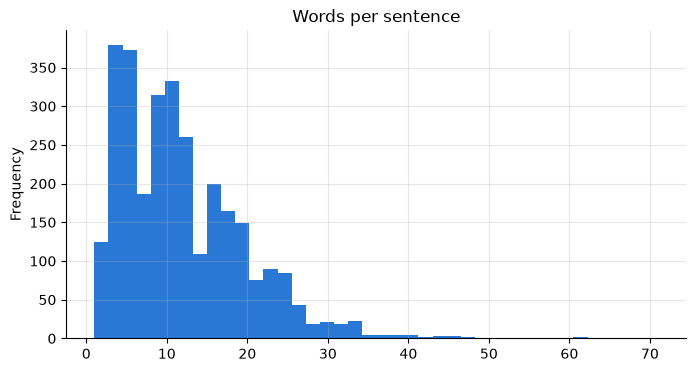

In [3]:
df["words"] = df["text"].str.split().str.len()
df["words"].plot.hist(bins=40, color=BLUE, title="Words per sentence")
df["words"].describe().round(1)

Perfectly balanced (50/50) and short texts. TF-IDF on unigrams + bigrams is a strong baseline for this size.

## 2. Split + compare TF-IDF + Logistic Regression vs Naive Bayes

In [4]:
from sklearn.model_selection import train_test_split
X_train, X_test, y_train, y_test = train_test_split(df["text"], df["label"], test_size=0.2, stratify=df["label"], random_state=42)
comparison = sentiment.compare_models(X_train, y_train)
comparison.round(4)

,model,cv_roc_auc,cv_f1,cv_accuracy,cv_roc_auc_std
0,tfidf_logistic_regression,0.9006,0.8180,0.8204,0.0118
1,tfidf_naive_bayes,0.8986,0.8108,0.8146,0.0148


## 3. Test-set evaluation

tfidf_logistic_regression
              precision    recall  f1-score   support

    negative       0.84      0.83      0.84       300
    positive       0.83      0.85      0.84       300

    accuracy                           0.84       600
   macro avg       0.84      0.84      0.84       600
weighted avg       0.84      0.84      0.84       600



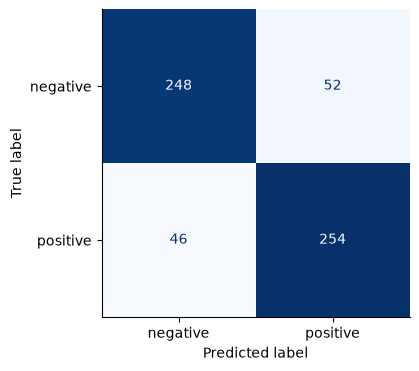

In [5]:
from sklearn.metrics import classification_report, ConfusionMatrixDisplay
best = comparison.iloc[0]["model"]
model = sentiment.candidates()[best].fit(X_train, y_train)
print(best)
print(classification_report(y_test, model.predict(X_test), target_names=["negative", "positive"]))
ConfusionMatrixDisplay.from_predictions(y_test, model.predict(X_test), display_labels=["negative", "positive"], cmap="Blues", colorbar=False)
plt.grid(False)

Most informative words (logistic regression coefficients):

In [6]:
if best.endswith("logistic_regression"):
    vocab = np.array(model.named_steps["tfidf"].get_feature_names_out())
    coef = model.named_steps["model"].coef_[0]
    order = np.argsort(coef)
    print("negative:", ", ".join(vocab[order[:15]]))
    print("positive:", ", ".join(vocab[order[-15:]]))

negative: not, bad, poor, worst, awful, don, disappointing, terrible, didn, not good, at, disappointment, the worst, sucked, then
positive: the best, well, beautiful, and, amazing, works, excellent, film, delicious, awesome, best, nice, love, good, great


## 4. From sentiment to ticket priority

In [7]:
examples = [
    "This is unacceptable! The app has been down all morning and our team can't log in. Fix it immediately.",
    "Please reset my password asap, I have a demo in an hour.",
    "The new reports page is confusing and slow, not happy with it.",
    "Can you send a copy of last month's invoice?",
    "Thanks, the support team was excellent and very friendly!",
]
pd.DataFrame(sentiment.classify(model, examples), index=[e[:60] + "…" for e in examples])

,sentiment,score,urgent,urgent_terms,priority
This is unacceptable! The app has been down all morning and …,positive,0.273,True,"[been down, can't log in, immediately]",medium
"Please reset my password asap, I have a demo in an hour.…",negative,-0.333,True,[asap],high
"The new reports page is confusing and slow, not happy with i…",neutral,-0.158,False,[],low
Can you send a copy of last month's invoice?…,neutral,-0.190,False,[],low
"Thanks, the support team was excellent and very friendly!…",positive,0.637,False,[],low


## 5. Final choice and limits

Highest CV ROC-AUC wins (shown above). Reviews are not support tickets, so two safeguards:
a **neutral band** (0.40 < P(positive) < 0.60) avoids over-confident labels on factual
requests, and **urgency is a transparent keyword rule** (outage, can't log in, refund,
immediately…), because reviews never talk about urgency. Agents can always override the
priority; an overridden ticket is never re-prioritised by the model.

In [8]:
metrics = sentiment.train(save=True)
{k: metrics[k] for k in ("chosen_model", "rows")} | {"test_roc_auc": metrics["test"]["roc_auc"], "test_f1": metrics["test"]["f1"]}

{'chosen_model': 'tfidf_logistic_regression',
 'rows': 3000,
 'test_roc_auc': 0.906,
 'test_f1': 0.835}